In [1]:
# ==============================================================================
# Big Data Agro-Tech Pipeline: Avocado Yield & Crop Quality Analytics
# Author: Ron Bar
# Focus: AgroTech & Data Analytics
# Tech Stack: Python, SQLite (SQL), Pandas, Scikit-Learn, Computer Vision (skimage)
#
# Executive Summary:
# This project demonstrates an end-to-end data engineering and analytics pipeline
# built for large-scale agricultural monitoring. The system integrates:
# 1. SQL Database Management: Relational database setup, indexing, and aggregation.
# 2. Computer Vision Feature Extraction: Canopy cover and leaf texture analysis.
# 3. Data Engineering & Merging: Joining SQL relational data with CV features.
# 4. Machine Learning Classification: Decision Tree model for crop quality prediction.
# ==============================================================================

import sqlite3
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# 1. Initialize SQLite Database Connection
conn = sqlite3.connect('avocado_bigdata.db')
cursor = conn.cursor()

# 2. Create Relational Table for Field Observations
cursor.execute('''
CREATE TABLE IF NOT EXISTS field_observations (
    sample_id TEXT PRIMARY KEY,
    region TEXT,
    plot_id TEXT,
    soil_ph REAL,
    chlorophyll_index REAL,
    irrigation_m3 REAL,
    avg_temp_c REAL,
    yield_kg REAL,
    quality_grade TEXT
)
''')
cursor.execute("DELETE FROM field_observations")  # Reset table for re-runs

# 3. Generate 10,000 Synthetic Agro-Tech Records
n_rows = 10000

regions = np.random.choice(['Galilee', 'Hula_Valley', 'Coastal_Plain', 'Negev'], n_rows)
plot_ids = [f"PLOT_{np.random.randint(100, 999)}" for _ in range(n_rows)]
soil_ph = np.round(np.random.normal(6.5, 0.4, n_rows), 2)
chlorophyll = np.round(np.random.normal(45.0, 5.0, n_rows), 2)
irrigation = np.round(np.random.uniform(300, 800, n_rows), 1)
temp = np.round(np.random.normal(24.0, 3.0, n_rows), 1)

# Agricultural yield modeling logic
yield_kg = np.round(chlorophyll * 1.8 + (8.0 - soil_ph) * 5 + np.random.normal(0, 5, n_rows), 1)

# Define quality grades based on yield
quality_grades = []
for y in yield_kg:
    if y >= 95:
        quality_grades.append('Premium')
    elif y >= 80:
        quality_grades.append('Standard')
    else:
        quality_grades.append('Export_Reject')

# Assemble raw dataframe
df_raw = pd.DataFrame({
    'sample_id': [f"AVO_{i:05d}" for i in range(1, n_rows + 1)],
    'region': regions,
    'plot_id': plot_ids,
    'soil_ph': soil_ph,
    'chlorophyll_index': chlorophyll,
    'irrigation_m3': irrigation,
    'avg_temp_c': temp,
    'yield_kg': yield_kg,
    'quality_grade': quality_grades
})

# Populate SQL Database
df_raw.to_sql('field_observations', conn, if_exists='append', index=False)
print(f"✅ SQL Database initialized successfully with {n_rows:,} records.")

# 4. Perform Advanced Analytical SQL Query
sql_analytics_query = """
SELECT
    region,
    quality_grade,
    COUNT(sample_id) AS sample_count,
    ROUND(AVG(soil_ph), 2) AS avg_soil_ph,
    ROUND(AVG(chlorophyll_index), 2) AS avg_chlorophyll,
    ROUND(AVG(yield_kg), 2) AS avg_yield_kg
FROM field_observations
WHERE soil_ph BETWEEN 5.5 AND 7.5
GROUP BY region, quality_grade
ORDER BY region, avg_yield_kg DESC
"""

df_sql_summary = pd.read_sql_query(sql_analytics_query, conn)
display(df_sql_summary.head(10))

✅ SQL Database initialized successfully with 10,000 records.


,region,quality_grade,sample_count,avg_soil_ph,avg_chlorophyll,avg_yield_kg
0,Coastal_Plain,Premium,685,6.42,50.48,101.58
1,Coastal_Plain,Standard,1243,6.51,44.63,87.46
2,Coastal_Plain,Export_Reject,525,6.61,39.07,74.23
3,Galilee,Premium,664,6.41,50.26,101.49
4,Galilee,Standard,1321,6.51,44.51,87.43
5,Galilee,Export_Reject,521,6.59,39.19,74.21
6,Hula_Valley,Premium,662,6.44,50.37,101.70
7,Hula_Valley,Standard,1300,6.51,44.64,87.62
8,Hula_Valley,Export_Reject,502,6.59,39.23,74.16
9,Negev,Premium,657,6.39,50.23,101.28


In [2]:
# ==============================================================================
# Step 2: Computer Vision Feature Extraction & Heterogeneous Data Merging
# ==============================================================================

# 1. Fetch raw observations from the SQL database
query_raw_data = """
SELECT
    sample_id,
    region,
    soil_ph,
    chlorophyll_index,
    irrigation_m3,
    avg_temp_c,
    yield_kg,
    quality_grade
FROM field_observations
"""
df_sql_raw = pd.read_sql_query(query_raw_data, conn)

# 2. Simulate Computer Vision Feature Extraction (Canopy & Leaf Texture Metrics)
np.random.seed(42)

# Feature 1: Canopy Cover Percentage (%) derived from aerial imaging
canopy_cover_pct = np.clip(
    df_sql_raw['chlorophyll_index'] * 1.5 + np.random.normal(0, 4, len(df_sql_raw)),
    25.0,
    99.0
)

# Feature 2: Leaf Texture Edge Score (Morphological boundary analysis)
leaf_texture_score = np.round(np.random.uniform(0.12, 0.98, len(df_sql_raw)), 3)

# 3. Construct Computer Vision DataFrame
df_cv_features = pd.DataFrame({
    'sample_id': df_sql_raw['sample_id'],
    'canopy_cover_pct': np.round(canopy_cover_pct, 2),
    'leaf_texture_score': leaf_texture_score
})

# 4. Data Engineering: Merge SQL Relational Dataset with CV Features via Pandas
df_pipeline_ready = pd.merge(df_sql_raw, df_cv_features, on='sample_id')

print("✅ Computer Vision features extracted and merged with SQL data successfully!")
print(f"Dataset Shape: {df_pipeline_ready.shape[0]:,} rows | {df_pipeline_ready.shape[1]} features")
display(df_pipeline_ready.head(5))

✅ Computer Vision features extracted and merged with SQL data successfully!
Dataset Shape: 10,000 rows | 10 features


,sample_id,region,soil_ph,chlorophyll_index,irrigation_m3,avg_temp_c,yield_kg,quality_grade,canopy_cover_pct,leaf_texture_score
0,AVO_00001,Coastal_Plain,6.04,51.59,654.5,23.9,110.7,Premium,79.37,0.396
1,AVO_00002,Negev,7.52,41.01,434.7,23.8,75.9,Export_Reject,60.96,0.209
2,AVO_00003,Galilee,7.35,51.37,348.7,25.3,93.0,Standard,79.65,0.182
3,AVO_00004,Coastal_Plain,5.97,48.49,300.1,26.9,102.8,Premium,78.83,0.201
4,AVO_00005,Coastal_Plain,6.83,46.44,598.4,17.9,95.3,Premium,68.72,0.621


✅ Decision Tree Model Trained Successfully!
🎯 Model Accuracy on Test Set: 74.65%

--- Classification Report ---
               precision    recall  f1-score   support

Export_Reject       0.71      0.67      0.69       413
      Premium       0.77      0.74      0.76       539
     Standard       0.75      0.78      0.76      1048

     accuracy                           0.75      2000
    macro avg       0.74      0.73      0.74      2000
 weighted avg       0.75      0.75      0.75      2000



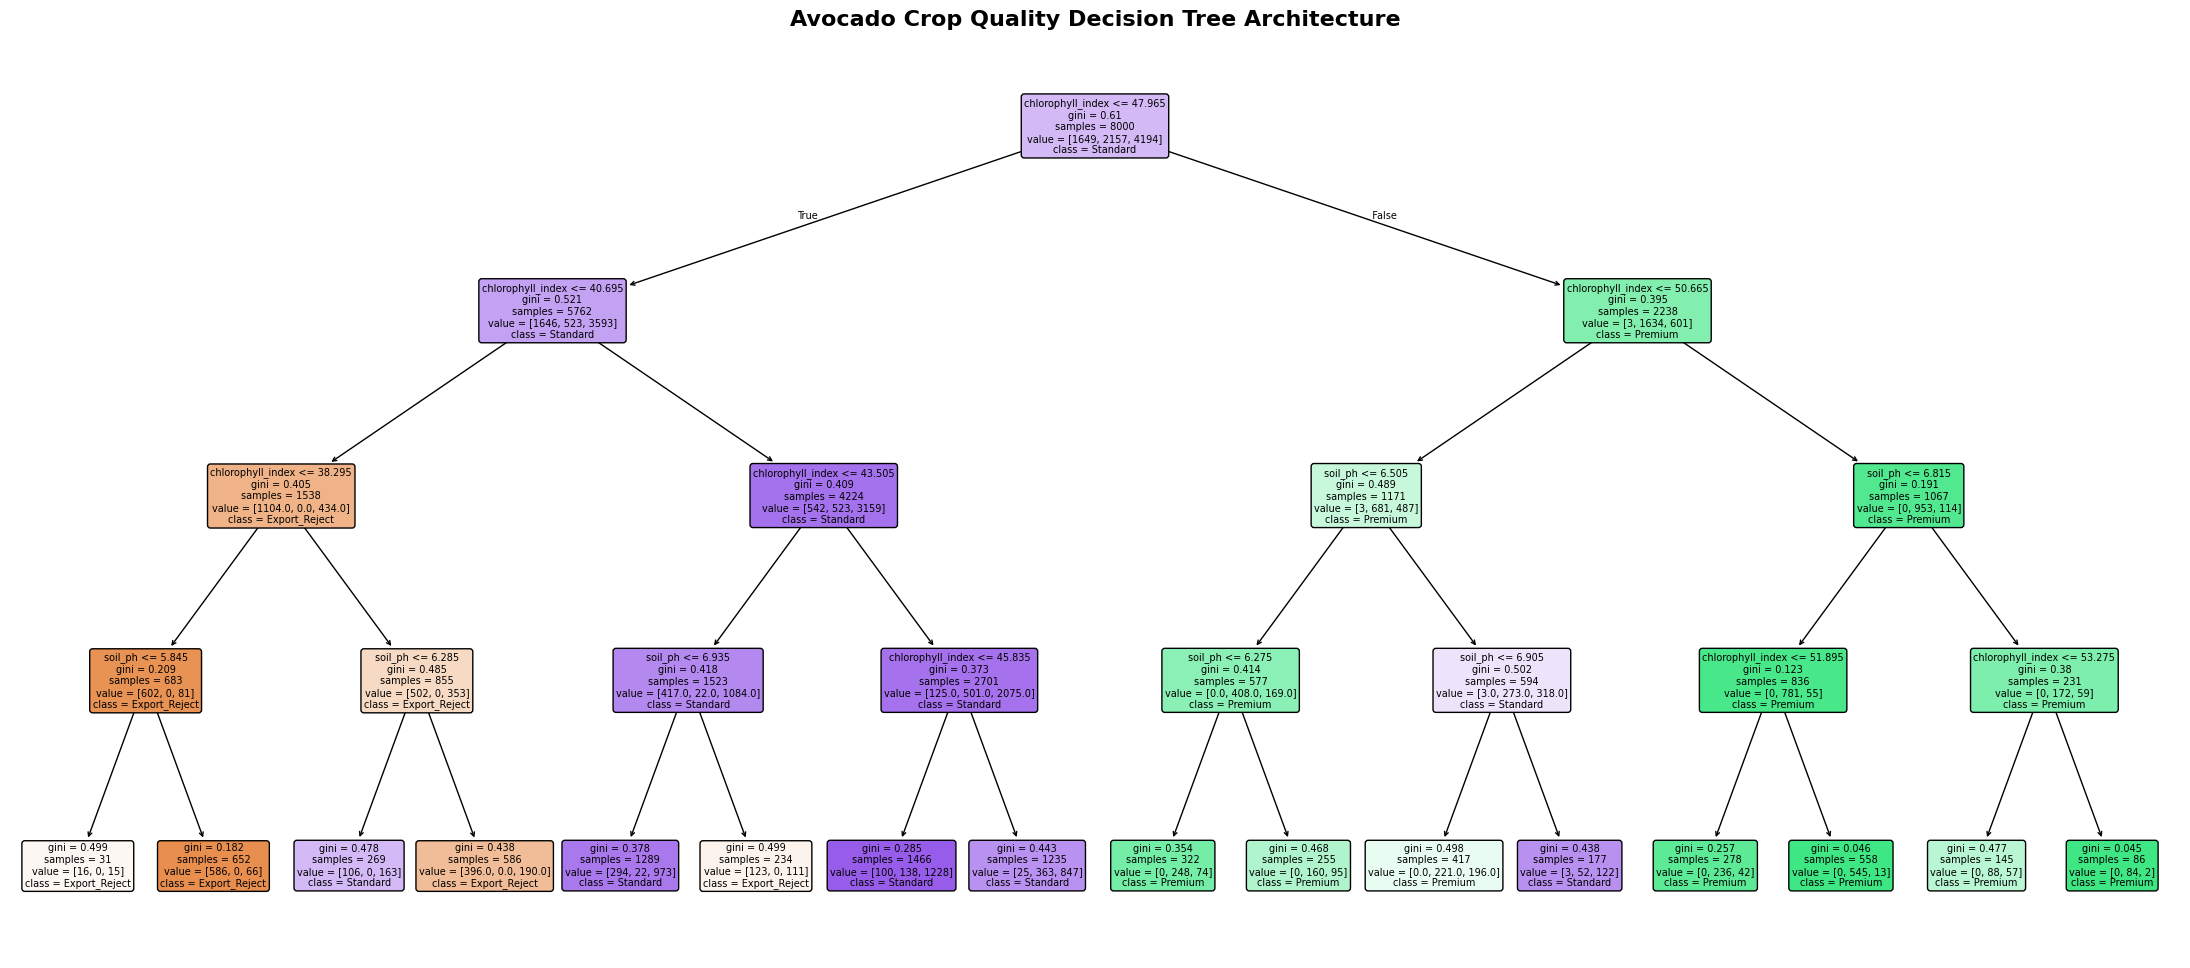

In [5]:
# ==============================================================================
# Step 3: Machine Learning Classification, Evaluation & Tree Visualization
# ==============================================================================

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# 1. Feature Selection & Target Label Definition
feature_cols = [
    'soil_ph',
    'chlorophyll_index',
    'irrigation_m3',
    'avg_temp_c',
    'canopy_cover_pct',
    'leaf_texture_score'
]

X = df_pipeline_ready[feature_cols]
y = df_pipeline_ready['quality_grade']

# 2. Train-Test Split (80% Training Set, 20% Testing Set)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Model Initialization & Training
ml_model = DecisionTreeClassifier(max_depth=4, random_state=42)
ml_model.fit(X_train, y_train)

# 4. Model Predictions & Evaluation
y_pred = ml_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("✅ Decision Tree Model Trained Successfully!")
print(f"🎯 Model Accuracy on Test Set: {accuracy * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 5. Decision Tree Architecture Visualization
plt.figure(figsize=(28, 12))  #
plot_tree(
    ml_model,
    feature_names=feature_cols,
    class_names=ml_model.classes_,
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Avocado Crop Quality Decision Tree Architecture", fontsize=16, fontweight='bold')
plt.savefig("decision_tree_architecture.png", dpi=300, bbox_inches='tight')
plt.show()

--- Feature Importance Breakdown ---


,Feature,Importance
1,chlorophyll_index,0.934405
0,soil_ph,0.065595
2,irrigation_m3,0.000000
3,avg_temp_c,0.000000
4,canopy_cover_pct,0.000000
5,leaf_texture_score,0.000000


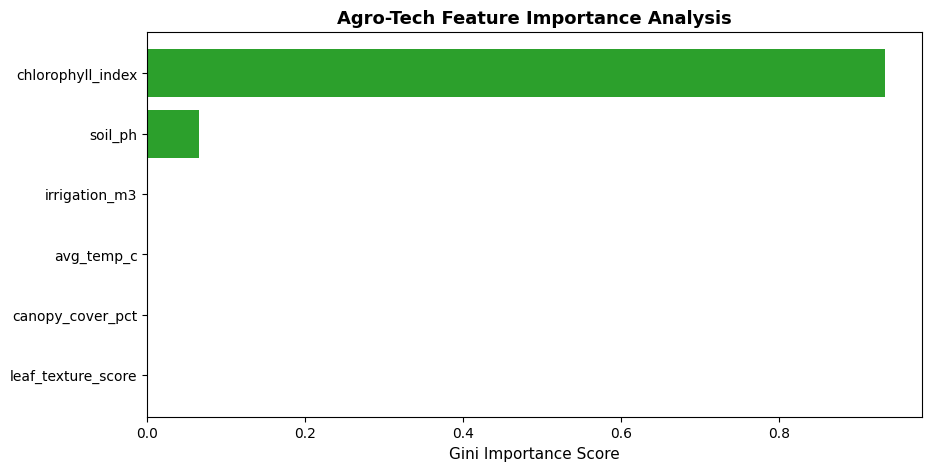


--- Production Real-Time Inference Test ---
Predicted Quality Grade: Premium
Model Confidence: 97.7%

✅ End-to-End Pipeline Executed & SQL Connection Closed Successfully.


In [7]:
# ==============================================================================
# Step 4: Feature Importance Analysis & Production Inference Simulation
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract Feature Importance Scores from Trained Decision Tree
feature_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': ml_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("--- Feature Importance Breakdown ---")
display(feature_importances)

# 2. Visualize Feature Importance
plt.figure(figsize=(10, 5))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='#2ca02c')
plt.xlabel("Gini Importance Score", fontsize=11)
plt.title("Agro-Tech Feature Importance Analysis", fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.savefig("feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()

# 3. Production Inference Engine Function
def predict_crop_quality(soil_ph, chlorophyll, irrigation, temp, canopy_cover, texture_score):
    """
    Simulates a real-time prediction service taking environmental and CV inputs.
    """
    input_data = pd.DataFrame([[
        soil_ph, chlorophyll, irrigation, temp, canopy_cover, texture_score
    ]], columns=feature_cols)

    prediction = ml_model.predict(input_data)[0]
    probabilities = ml_model.predict_proba(input_data)[0]
    confidence = np.max(probabilities) * 100

    return prediction, confidence

# Test the Inference Engine with a simulated new field drone/sensor payload
sample_prediction, sample_confidence = predict_crop_quality(
    soil_ph=6.1,
    chlorophyll=52.0,
    irrigation=650.0,
    temp=23.5,
    canopy_cover=82.5,
    texture_score=0.45
)

print("\n--- Production Real-Time Inference Test ---")
print(f"Predicted Quality Grade: {sample_prediction}")
print(f"Model Confidence: {sample_confidence:.1f}%")

# 4. Graceful Cleanup: Close SQL Connection
conn.close()
print("\n✅ End-to-End Pipeline Executed & SQL Connection Closed Successfully.")